In [1]:
import requests
import pandas as pd
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler

In [2]:
import pandas as pd

def pivot_and_clean_data(csv_path):
    # Load raw long-format data
    df = pd.read_csv(csv_path)

    # Pivot the pollutant_id into columns
    df_wide = df.pivot_table(
        index=['station', 'last_update'],
        columns='pollutant_id',
        values='pollutant_avg'
    ).reset_index()

    # Clean up column names
    df_wide.columns.name = None
    df_wide = df_wide.rename(columns=str.lower)

    # Rename to match model convention
    rename_map = {
        'pm2.5': 'pm25',
        'pm10': 'pm10',
        'no2': 'no2',
        'so2': 'so2',
        'co': 'co',
        'ozone': 'o3'
    }
    df_wide = df_wide.rename(columns=rename_map)

    # Keep only necessary columns
    model_features = ['pm25', 'pm10', 'no2', 'so2', 'co', 'o3']
    df_wide = df_wide.dropna(subset=model_features, how='all')

    print("Pivoted & Cleaned Shape:", df_wide.shape)
    return df_wide, model_features


In [3]:
csv_path = "C:/Users/priya/Downloads/Real-time-air-quality-index.csv"
df_wide, features = pivot_and_clean_data(csv_path)

Pivoted & Cleaned Shape: (460, 9)


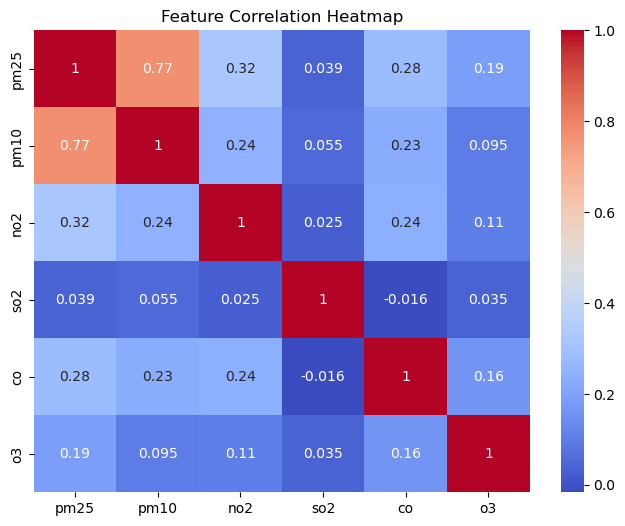

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.heatmap(df_wide[features].corr(), annot=True, cmap='coolwarm')
plt.title('Feature Correlation Heatmap')
plt.show()

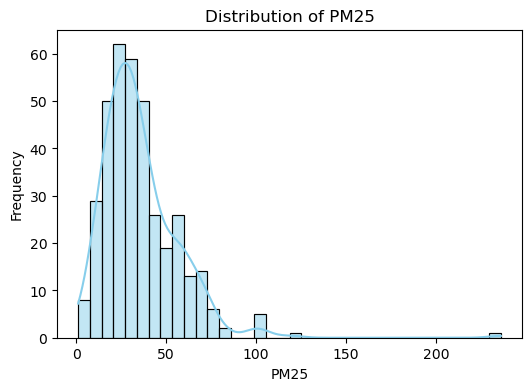

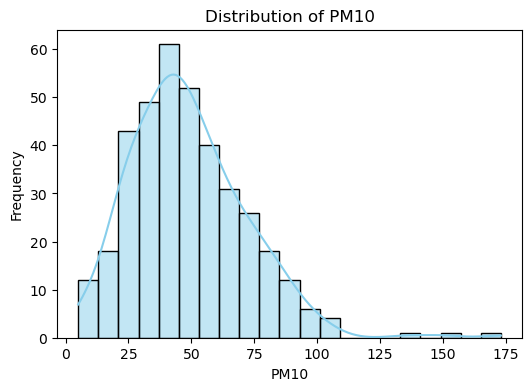

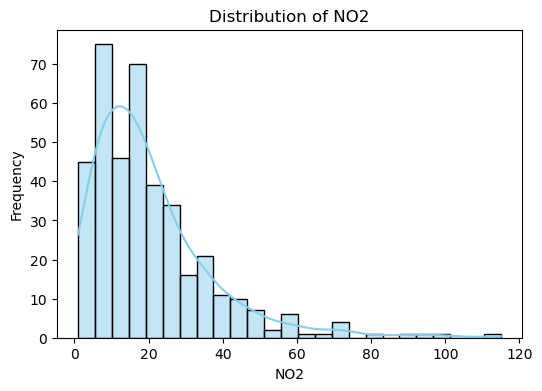

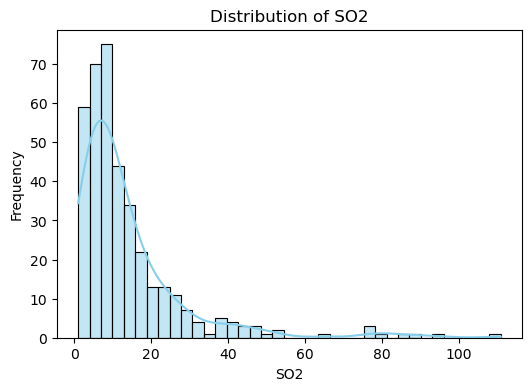

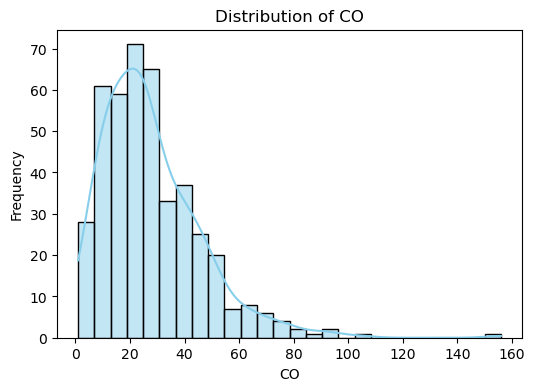

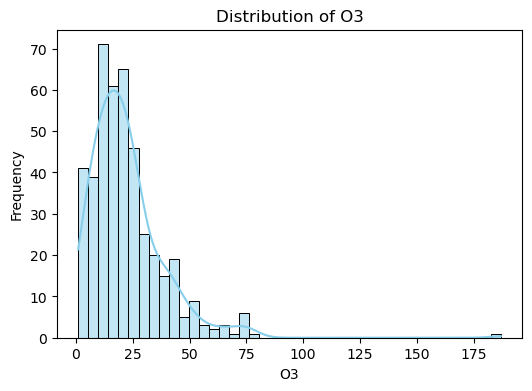

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

for feature in features:
    if feature in df_wide.columns:
        plt.figure(figsize=(6, 4))
        sns.histplot(df_wide[feature].dropna(), kde=True, color="skyblue")
        plt.title(f'Distribution of {feature.upper()}')
        plt.xlabel(feature.upper())
        plt.ylabel("Frequency")
        plt.show()

C:\Users\priya\AppData\Local\Temp\ipykernel_6552\665048805.py:10: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


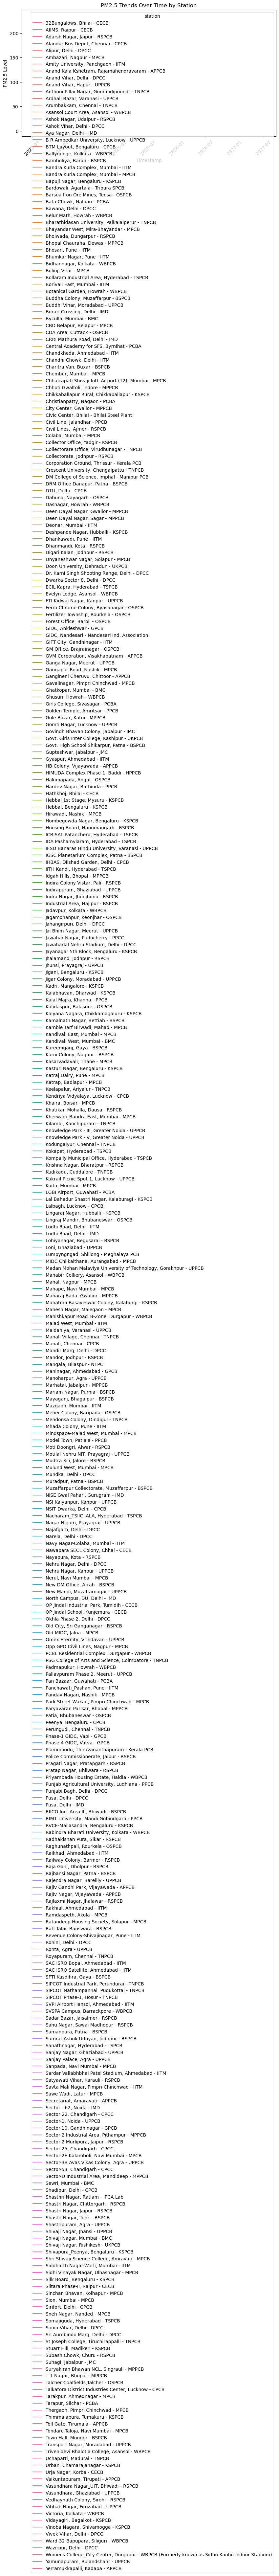

In [6]:
plt.figure(figsize=(10, 5))
df_pm25 = df_wide[['last_update', 'station', 'pm25']].dropna()
df_pm25['last_update'] = pd.to_datetime(df_pm25['last_update'])

sns.lineplot(data=df_pm25, x='last_update', y='pm25', hue='station')
plt.title("PM2.5 Trends Over Time by Station")
plt.xlabel("Timestamp")
plt.ylabel("PM2.5 Level")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

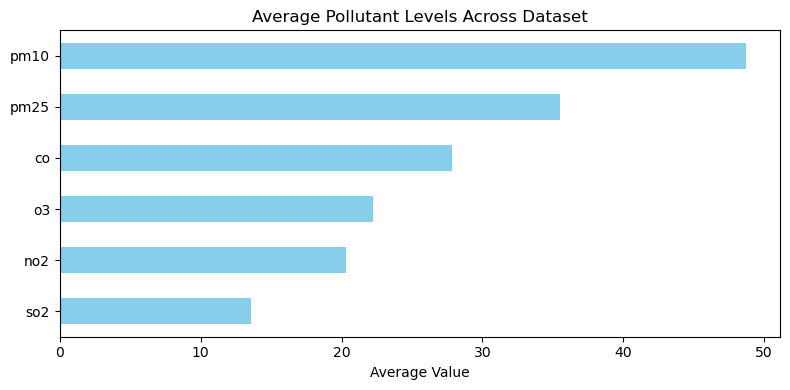

In [7]:
avg_pollutants = df_wide[features].mean().sort_values()

plt.figure(figsize=(8, 4))
avg_pollutants.plot(kind='barh', color='skyblue')
plt.title("Average Pollutant Levels Across Dataset")
plt.xlabel("Average Value")
plt.tight_layout()
plt.show()

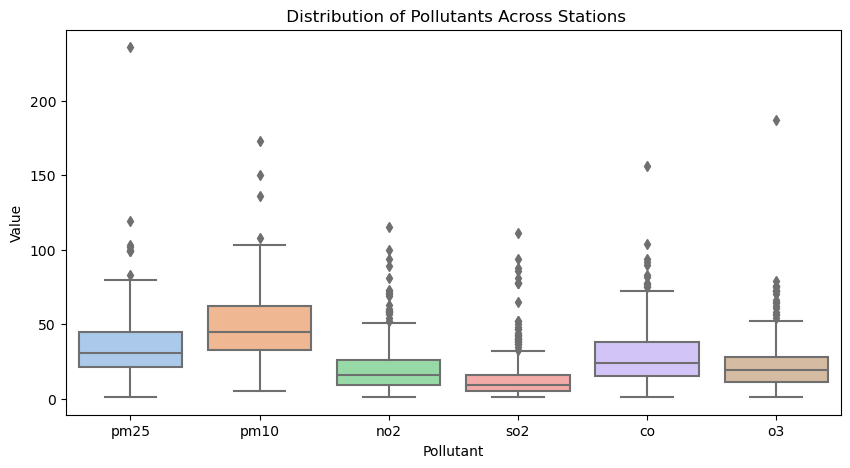

In [8]:
plt.figure(figsize=(10, 5))
df_melt = df_wide.melt(id_vars=['station'], value_vars=features, var_name='Pollutant', value_name='Value')
sns.boxplot(data=df_melt, x='Pollutant', y='Value', palette='pastel')
plt.title(" Distribution of Pollutants Across Stations")
plt.show()

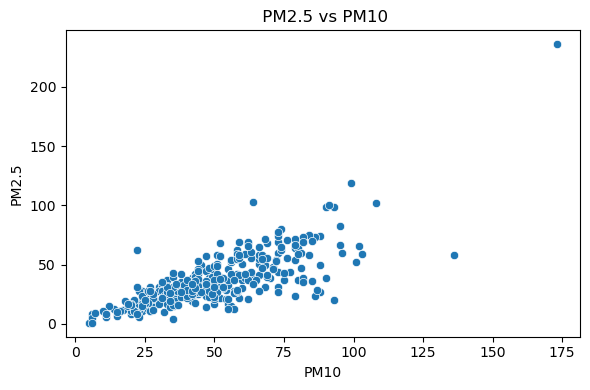

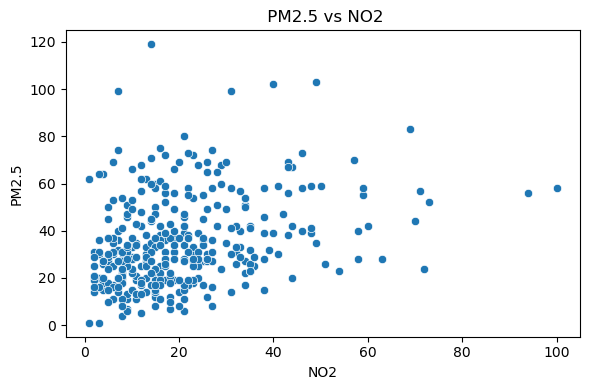

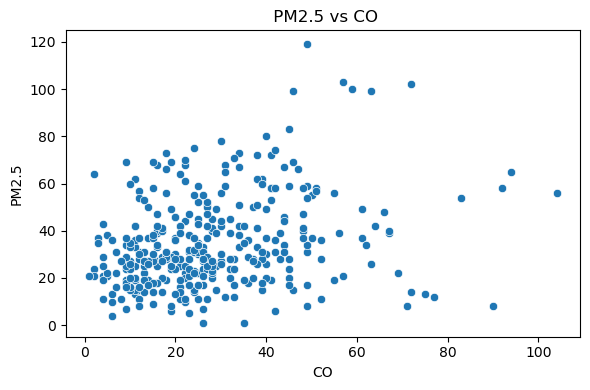

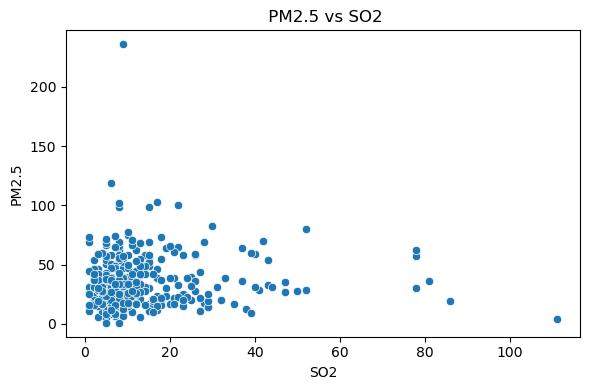

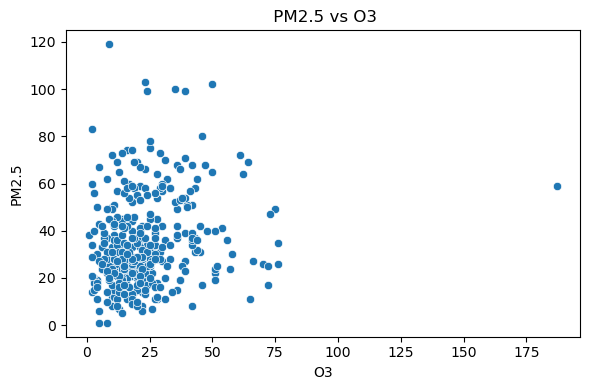

In [9]:
for col in ['pm10', 'no2', 'co', 'so2', 'o3']:
    if col in df_wide.columns:
        plt.figure(figsize=(6, 4))
        sns.scatterplot(data=df_wide, x=col, y='pm25')
        plt.title(f" PM2.5 vs {col.upper()}")
        plt.xlabel(col.upper())
        plt.ylabel("PM2.5")
        plt.tight_layout()
        plt.show()

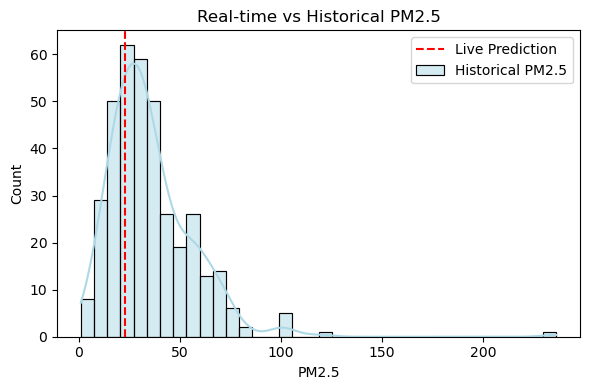

In [10]:
#Live vs Historical Comparison (Real-time overlay)
predicted_pm25 = 22.9

plt.figure(figsize=(6, 4))
sns.histplot(df_wide['pm25'].dropna(), kde=True, color='lightblue', label='Historical PM2.5')
plt.axvline(predicted_pm25, color='red', linestyle='--', label='Live Prediction')
plt.title('Real-time vs Historical PM2.5')
plt.xlabel('PM2.5')
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
def train_model(df_wide, features):
    df_clean = df_wide.dropna(subset=['pm25'])  # Using PM2.5 as target

    # Input = all features except target
    X = df_clean[features].drop(columns=['pm25'])  # e.g., pm10, no2, ...
    y = df_clean['pm25']  # Target = pm25

    # Fill missing values in X
    X = X.fillna(0)

    # Scale input
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Train/test split
    from sklearn.model_selection import train_test_split
    X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

    # Train 2 models
    from sklearn.ensemble import RandomForestRegressor
    from xgboost import XGBRegressor
    from sklearn.metrics import mean_squared_error

    models = {
        "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
        "XGBoost": XGBRegressor(n_estimators=100, random_state=42, verbosity=0)
    }

    best_model = None
    lowest_rmse = float("inf")

    for name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        rmse = mean_squared_error(y_test, y_pred, squared=False)
        print(f"{name} RMSE: {rmse:.2f}")
        if rmse < lowest_rmse:
            best_model = model
            best_name = name
            lowest_rmse = rmse

    print(f"\n Best Model: {best_name} (RMSE: {lowest_rmse:.2f})")
    return best_model, scaler, X.columns.tolist()


In [12]:
model, scaler, input_features = train_model(df_wide, features)


Random Forest RMSE: 13.98
XGBoost RMSE: 16.83

 Best Model: Random Forest (RMSE: 13.98)


In [13]:
# Make it global for reuse across all functions
def aqi_category(pm25):
    if pm25 <= 50:
        return "Good"
    elif pm25 <= 100:
        return "Satisfactory"
    elif pm25 <= 200:
        return "Moderate"
    elif pm25 <= 300:
        return "Poor"
    elif pm25 <= 400:
        return "Very Poor"
    else:
        return "Severe"

In [14]:
import requests
import numpy as np

def fetch_aqi_data(city="delhi"):
    token = "160e856119d9b9fd3ea7c985dac0b9e0e76a839c"
    url = f"https://api.waqi.info/feed/{city}/?token={token}"
    response = requests.get(url)

    try:
        data = response.json()
        if data["status"] != "ok":
            print("Failed to fetch:", data.get("data"))
            return None
        iaqi = data["data"]["iaqi"]
        return {k.lower(): v['v'] for k, v in iaqi.items()}
    except Exception as e:
        print("API Error:", e)
        return None
    
def predict_realtime_pm25(model, scaler, input_features, city="delhi"):
    live_data = fetch_aqi_data(city)
    if not live_data:
        return

    input_vector = [live_data.get(f, 0) for f in input_features]
    input_df = pd.DataFrame([input_vector], columns=input_features)
    input_scaled = scaler.transform(input_df)

    predicted_pm25 = model.predict(input_scaled)[0]
    category = aqi_category(predicted_pm25)

    print(f"Predicted PM2.5 (AQI Proxy) for {city.title()}: {predicted_pm25:.2f}")
    print(f"AQI Category: {category}")


In [15]:
predict_realtime_pm25(model, scaler, input_features, city="delhi")

Predicted PM2.5 (AQI Proxy) for Delhi: 28.05
AQI Category: Good


In [17]:
import matplotlib.pyplot as plt

def plot_pm25_gauge(predicted_pm25):
    category = aqi_category(predicted_pm25)
    bounds = [0, 50, 100, 200, 300, 400, 500]
    labels = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
    colors = ['green', 'yellow', 'orange', 'red', 'purple', 'maroon']

    plt.figure(figsize=(10, 1.5))
    for i in range(len(bounds)-1):
        plt.barh(0, width=bounds[i+1]-bounds[i], left=bounds[i], height=0.5, color=colors[i], edgecolor='black')
        plt.text((bounds[i] + bounds[i+1])/2, 0.6, labels[i], ha='center', fontsize=9)

    plt.axvline(predicted_pm25, color='black', linewidth=3)
    plt.title(f' Predicted PM2.5: {predicted_pm25:.2f} ({category})')
    plt.yticks([])
    plt.xlim(0, 500)
    plt.xlabel("PM2.5 Value")
    plt.grid(False)
    plt.show()

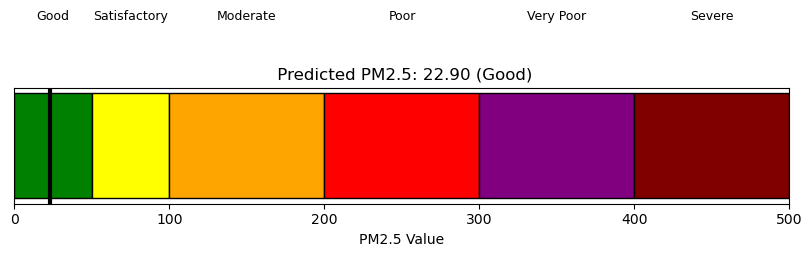

In [18]:
plot_pm25_gauge(predicted_pm25=22.90)

In [19]:
import time

def auto_refresh_predict(model, scaler, input_features, city="delhi", interval=300, cycles=5):
    print(f"📡 Starting auto-refresh for {city.title()} every {interval} seconds...\n")

    for i in range(cycles):
        print(f"Cycle {i+1}/{cycles} — {time.strftime('%Y-%m-%d %H:%M:%S')}")
        predict_realtime_pm25(model, scaler, input_features, city)
        print("-" * 50)
        time.sleep(interval)  # Wait for X seconds

# Example: refresh every 5 mins, for 3 cycles
auto_refresh_predict(model, scaler, input_features, city="delhi", interval=10, cycles=3)


📡 Starting auto-refresh for Delhi every 10 seconds...

Cycle 1/3 — 2025-07-25 21:20:09
Predicted PM2.5 (AQI Proxy) for Delhi: 37.57
AQI Category: Good
--------------------------------------------------
Cycle 2/3 — 2025-07-25 21:20:20
Predicted PM2.5 (AQI Proxy) for Delhi: 37.57
AQI Category: Good
--------------------------------------------------
Cycle 3/3 — 2025-07-25 21:20:31
Predicted PM2.5 (AQI Proxy) for Delhi: 37.57
AQI Category: Good
--------------------------------------------------
